# MF-Env Scenario Demos

This notebook walks through four multi-agent scenarios. 


## Getting Started
This cell represents boiler-plate code and should be run before running any scenario.

In [1]:
from pathlib import Path
import logging
import sys
import warnings

# Keep notebook output focused on demo results.
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

# Make this checkout importable from the notebook without installing its dependencies.
repo_root = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "gym_mf_envs" / "__init__.py").is_file()),
    None,
)
if repo_root is None:
    raise RuntimeError(
        "Cannot locate the repository. Open Jupyter from the repository directory."
    )
sys.path.insert(0, str(repo_root))

import gymnasium as gym
import gym_mf_envs  # Registers the MF-Envs environments with Gymnasium.
from gym_mf_envs.wrappers import (
    MultiDiscreteActionWrapper,
    FlattenObservationWrapper,
    AnyPopulationAllAgentDoneWrapper,
    PopulationRewardWrapper,
)
from IPython.display import HTML, display


def display_rps_distributions(mean_fields):
    """Render the final RPS state distributions as a styled pair of bar charts."""
    panels = []
    team_styles = {"blue": ("Blue", "#3978f6"), "red": ("Red", "#e45468")}
    state_names = ("Rock", "Paper", "Scissors")
    for team, (label, color) in team_styles.items():
        probabilities = mean_fields[team]["mf_flat"]
        bars = []
        for state, probability in zip(state_names, probabilities):
            value = float(probability)
            width = max(0.0, min(value, 1.0)) * 100
            bars.append(
                f"<div style='display:grid;grid-template-columns:72px 1fr 48px;gap:10px;"
                f"align-items:center;margin:12px 0;color:#334155;font-size:13px;'>"
                f"<span>{state}</span><div style='height:10px;background:#edf2f7;border-radius:99px;overflow:hidden;'>"
                f"<div style='height:100%;width:{width:.2f}%;background:{color};border-radius:99px;'></div></div>"
                f"<span style='text-align:right;font-variant-numeric:tabular-nums;'>{value:.3f}</span></div>"
            )
        panels.append(
            f"<section style='flex:1;min-width:240px;padding:18px 20px;background:#fff;"
            f"border:1px solid #e2e8f0;border-radius:16px;'>"
            f"<h3 style='margin:0 0 14px;color:{color};font:700 16px system-ui;'>{label} team</h3>"
            f"{''.join(bars)}</section>"
        )
    display(HTML(
        "<div style='max-width:760px;margin:20px auto;font-family:system-ui,-apple-system,sans-serif;'>"
        "<div style='margin:0 0 12px;color:#0f172a;font-size:19px;font-weight:700;'>Final population distributions</div>"
        "<div style='display:flex;flex-wrap:wrap;gap:14px;'>" + ''.join(panels) + "</div></div>"
    ))


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## 1. Constrained Rock-Paper-Scissors

We use a population-based rock–paper–scissors (RPS) game to validate the convergence of MF-MAPPO to equilibrium before deploying it to more complex scenarios. This setting is chosen for its simplicity, which allows the equilibrium to be computed analytically. The individual state space is {Rock (R), Paper (P), Scissors (S)} and we consider a restriction of the action space to either move clockwise (R to P, P to S, S to R) or remain on current state.

In [2]:
env = gym.make(
    "gym_mf_envs/MF-RPSMFEnv-v0",
    num_population=2,
    num_agent_dict={"blue": 100, "red": 100},
    render_mode=None,
)
env = AnyPopulationAllAgentDoneWrapper(MultiDiscreteActionWrapper(env))
base_env = env.unwrapped
obs, info = env.reset(seed=3)
for _ in range(5):
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
    if terminated or truncated:
        break

display_rps_distributions(base_env.mf_info)
env.close()

print("Rock-paper-scissors demo completed.")


Rock-paper-scissors demo completed.


## 2. Battlefield

We consider a grid-based battlefield scenario in which Blue agents aim to reach designated targets (green cells), while Red agents attempt to block their access. At each cell, an activation–deactivation mechanism governs interactions: an agent’s probability of being deactivated is proportional to the opponent’s numerical advantage relative to its own team’s presence in that cell. This induces strategic grouping and dispersion behaviors. The Blue team seeks to maximize the fraction of its population that reaches the target cells, while the Red team aims to minimize this quantity, resulting in a zero-sum objective.

We present this scenario under randomly samples actions for all agents across both the teams.


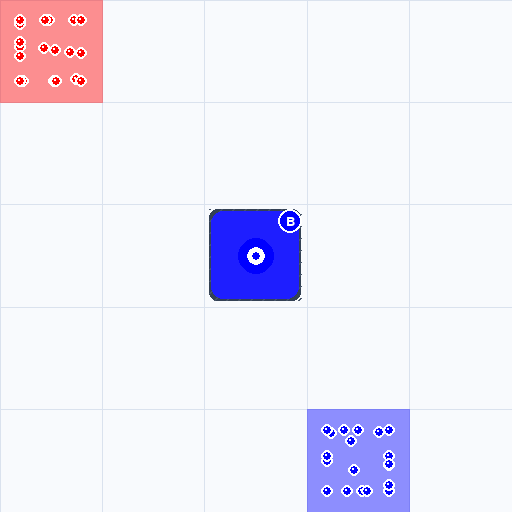

Battlefield demo completed.


In [ ]:
env = gym.make(
    "gym_mf_envs/MF-Battle-v0",
    num_population=2,
    num_agent_dict={"blue": 50, "red": 50},
    action_map_dict={
        "blue": [(0, 1), (1, 0), (0, -1), (-1, 0), (0, 0)],
        "red": [(0, 1), (1, 0), (0, -1), (-1, 0), (0, 0)],
    },
    grid_size=(5, 5),
    random_init_targets_dict={"blue": False, "red": False},
    n_targets_dict={"blue": 1, "red": 0},
    target_locations_dict={"blue": [(2, 2)], "red": []},
    n_obstacles_dict={"blue": 0, "red": 1},
    identical_grid_world=False,
    obstacle_locations_dict={"blue": [], "red": [(2, 2)]},
    penetrable_obstacles_dict={"blue": False, "red": False},
    render_mode="rgb_array",
)

env = PopulationRewardWrapper(AnyPopulationAllAgentDoneWrapper(
    FlattenObservationWrapper(MultiDiscreteActionWrapper(env))))

base_env = env.unwrapped
obs, info = env.reset(seed=1)
base_env.render()  # Capture the initial battlefield state.
for _ in range(10):
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
    base_env.render()  # Capture the state after this action.
    if terminated or truncated:
        break

base_env.display_gif(duration=0.08, loop=0, title="Battlefield", caption="Blue and red mean-fields · blue B bullseye: Blue target · hatched tiles: obstacles · pale agents: deactivated")
print("Battlefield demo completed.")

## 3. Epidemiology

The epidemiology scenario models populations moving through a grid with health-related states and a hospital location (brown). Red agents emulate a virus that infects the Blue population, with infected Blue agents further spreading the disease. The Blue team aims to maximize the size of its healthy population. Accordingly, Blue agents avoid infected peers and move toward hospital states for recovery, while the Red (virus) team tracks the Blue population and block access to hospitals.


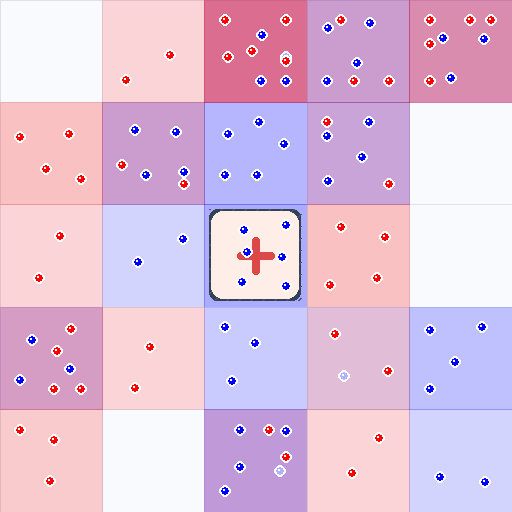

Epidemiology demo completed.


In [ ]:
env = gym.make(
    "gym_mf_envs/MF-Virus-v0",
    num_population=2,
    num_agent_dict={"blue": 50, "red": 50},
    action_map_dict={
        "blue": [(0, 1), (1, 0), (0, -1), (-1, 0), (0, 0)],
        "red": [(0, 1), (1, 0), (0, -1), (-1, 0), (0, 0)],
    },
    grid_size=(5, 5),
    random_init_targets_dict={"blue": False, "red": False},
    n_targets_dict={"blue": 0, "red": 0},
    target_locations_dict={"blue": [], "red": []},
    n_hospitals_dict={"blue": 1, "red": 0},
    hospital_locations_dict={"blue": [(2, 2)], "red": []},
    n_obstacles_dict={"blue": 0, "red": 1},
    identical_grid_world=False,
    obstacle_locations_dict={"blue": [], "red": [(2, 2)]},
    penetrable_obstacles_dict={"blue": False, "red": False},
    render_mode="rgb_array",
)

env = PopulationRewardWrapper(AnyPopulationAllAgentDoneWrapper(
    FlattenObservationWrapper(MultiDiscreteActionWrapper(env))))

base_env = env.unwrapped
obs, info = env.reset(seed=1)
base_env.render()  # Capture the initial state.
for _ in range(10):
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
    base_env.render()  # Capture the state after this action.
    if terminated or truncated:
        break

base_env.display_gif(duration=0.08, loop=0, title="Epidemiology", caption="Blue and red mean-fields · red cross: hospital · pale agents: deactivated")
print("Epidemiology demo completed.")


## 4. Navigation

Two populations navigate toward separate targets on a shared grid. Obstacles shape the routes, and the fixed action sequences below illustrate how coordinated movement can be applied over several steps.

Identical grid world is set to True. All population shares the same grid world (obstacles), targets can still be different.



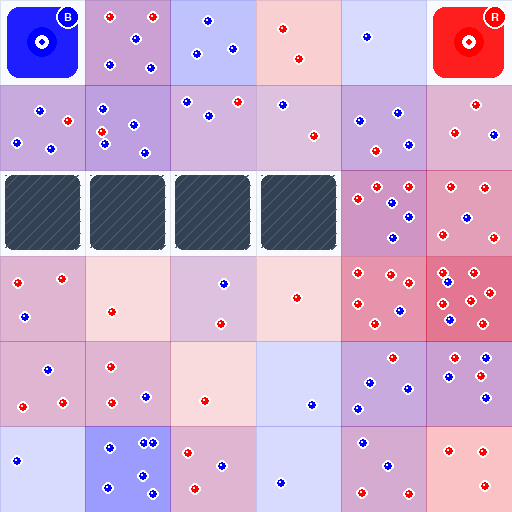

Navigation demo completed.


In [ ]:
env = gym.make(
    "gym_mf_envs/MF-Nav-v0",
    num_population=2,
    num_agent_dict={"blue": 50, "red": 50},
    action_map_dict={
        "blue": [(0, 1), (1, 0), (0, -1), (-1, 0), (0, 0)],
        "red": [(0, 1), (1, 0), (0, -1), (-1, 0), (0, 0)],
    },
    grid_size=(6, 6),
    random_init_targets_dict={"blue": False, "red": False},
    n_targets_dict={"blue": 1, "red": 1},
    target_locations_dict={"blue": [(0, 0)], "red": [(5, 0)]},
    n_obstacles_dict={"blue": 4, "red": 4},
    obstacle_locations_dict={"blue": [(i, 2) for i in range(4)], "red": [(i, 2) for i in range(4)]},
    identical_grid_world=True,
    penetrable_obstacles_dict={"blue": False, "red": False},
    random_init_obstacles_dict={"identical": False},
    render_mode="rgb_array",
)
env = AnyPopulationAllAgentDoneWrapper(FlattenObservationWrapper(MultiDiscreteActionWrapper(env)))

base_env = env.unwrapped
obs, info = env.reset(seed=1)
base_env.render()  # Capture the initial state.
for _ in range(10):
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
    base_env.render()  # Capture the state after this action.
    if terminated or truncated:
        break

base_env.display_gif(duration=0.08, loop=0, title="Navigation", caption="Blue and red mean-fields · B/R bullseyes: Blue/Red targets · hatched tiles: obstacles")
print("Navigation demo completed.")
